# Simulation method Project
**Team : Adrien Besson - Dax Au - Nathan Berbinau - Raphael Baran - Noe Coudert**

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## Part 1 : Ratio of Uniforms

In [6]:
n=100000
count=0
sim=[]
while(len(sim)<n):
    count+=1
    u1=np.random.uniform(0, 1)
    u2=np.random.uniform(0, 1)
    if(u1 <= np.exp(-0.25*(u2/u1)**2)):
        Z = u2/u1
        sim.append(Z)

In [7]:
count

159794

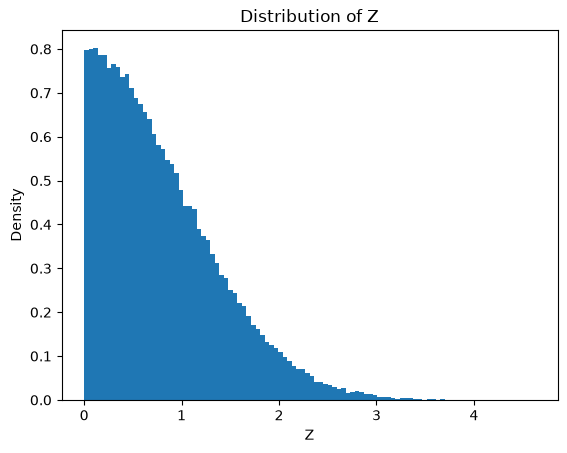

In [8]:
plt.hist(sim, bins=100, density=True)
plt.title("Distribution of Z")
plt.xlabel("Z")
plt.ylabel("Density")
plt.show()

The distribution of Z looks like the positive half of the normal law distribution

## Part 2 : Importance Sampling

**Question 1 :  Write the solution using closed formula (Black-Scholes). What happens when you evaluate this formula?**

In [9]:
S0=53.6
r=0.015
sigma=0.235

T=1
K=650000

Black-Scholes Formula for an European Option :
$$C=S_0*N(d_1)-K*e^{-rT}*N(d_2)$$

For a Digital Call Option :
$$D = e^{-rT}*N(d_2)$$

$$d_1 = \frac{ln(S_0/K) + (r + \sigma^2/2)T}{\sigma \sqrt{T}}$$

$$d_2 = d_1 - \sigma \sqrt{T} = \frac{ln(S_0/K) + (r - \sigma^2/2)T}{\sigma \sqrt{T}}$$


To find how many Digital calls are worth a European Call we will need to look at the ratio C/D

In [10]:
d1=(np.log(S0/K)+(r+sigma**2/2)*T)/(sigma*np.sqrt(T))
d2=d1-sigma*np.sqrt(T)

In [11]:
print("d1:", d1)
print("d2:", d2)

d1: -39.8321960587024
d2: -40.0671960587024


In [12]:
Nd1=norm.cdf(d1)
Nd2=norm.cdf(d2)
print("N(d1):", Nd1)
print("N(d2):", Nd2)

N(d1): 0.0
N(d2): 0.0


In [13]:
C=S0*Nd1-K*np.exp(-r*T)*Nd2
D=np.exp(-r*T)*Nd2
print("Call option price:", C)
print("Digital call option price:", D)

Call option price: 0.0
Digital call option price: 0.0


We have a problem because we obtain that both prices are worth 0 so we can't find any ratio as we can't do 0/0
This is due to the strike K being very high compare to the strike S0, and so the calculated d1 and d2 are very far in the negative numbers d1=-39.83 and d2=-40.07. When taking the standard normal distribution of this d1 and d2 they are too far in the negative that we get a probability of 0 for both and so the prices of both options will be 0.

**Question 2 :Apply the principle of importance sampling to estimate the ratio. Explain how the trick below is used.**

The issue we had before is that we were far out of the money so we f couldn't reach K=650000, and so Importance Sampling the goal is to use a new density function g.

We shift the mean (drift) of Z from to a new value $\mu$ so that the asset $S_t$ that we consider hit the strike K on average. And so now we will be half the time in the money and won't get values equal to 0 for the European Call option and Digital Call option. We choose $\mu = -d_2 = 40.067$

We then have to multiply the average payoff $h(X_{k})$ by the Randon-Nikodym $\frac{f(X_{k})}{g(X_{k})}$  \
f being the density function of a N(0,1)  $f(x) = \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{x^2}{2}\right)$    \
g being the density function of a N(mu,1) $g(x) = \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2}\right)$

We create a Box Muller function to generate the Random Normal Law

In [14]:
def Box_Muller(n):
    u1=np.random.rand(n)
    u2=np.random.rand(n)
    R=-2*np.log(u1)
    theta=2*np.pi*u2
    return np.sqrt(R)*np.cos(theta),np.sqrt(R)*np.sin(theta)

In [15]:
N = 100000
mu=-d2

Z,_=Box_Muller(N)
X=mu+Z
St=S0*np.exp((r-(sigma**2)/2)*T+sigma*np.sqrt(T)*X)
payoff_C = np.maximum(St - K, 0)
payoff_D = (St > K).astype(float)

In [16]:
St

array([713859.42823311, 785709.20090868, 790951.4407422 , ...,
       799052.48616839, 826461.94848086, 476661.25883804], shape=(100000,))

The issue we had before is that we were far out of the money so we f couldn't reach K=650000, and so Importance Sampling the goal is to use a new density function g.
For this we want to do a change of measure using the randon-NIKO, and find a drift mu, such that the we use a normal law N(mu,1), For this we put St=K and isolate x, that will be our mu and it will be equal to -d2, to be able to be half the time in the money and half the time out of the money. 
Now we take the densities of the functions, for N(O,1) f=... and for N(mu,1) g=... . We now want to apply the theorem Random Nikodin with the weight f/g. We calculate the Ratio f/g and we get $= \exp\left(\frac{-2\mu x + \mu^2}{2}\right)$. Finally we get li that is the ln of this ratio and equal to $= -\mu x + \frac{1}{2}\mu^2$

Now we calulate $f(X_k)/g(X_k)$

$$\frac{f(x)}{g(x)} = \frac{\frac{1}{\sqrt{2\pi}} \exp\left(-\frac{x^2}{2}\right)}{\frac{1}{\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2}\right)}$$

$$= \frac{\exp\left(-\frac{x^2}{2}\right)}{\exp\left(-\frac{(x-\mu)^2}{2}\right)}$$
$$= \exp\left(-\frac{x^2}{2} - \left(-\frac{(x-\mu)^2}{2}\right)\right)$$
$$= \exp\left(-\frac{x^2}{2} + \frac{x^2 - 2\mu x + \mu^2}{2}\right)$$
$$= \exp\left(\frac{-2\mu x + \mu^2}{2}\right)$$

And now we take the Logarithm of this function $l_i$
$$l_i = \ln\left(\frac{f(x)}{g(x)}\right)$$
$$= -\mu x + \frac{1}{2}\mu^2$$

In [17]:
l_i = -mu * X + 0.5 * mu**2
# A REECRIRE exp-400 donc on doit avoir un exponantiel plus grand
C = 500
weight=np.exp(l_i + C)
ratio=np.sum(payoff_C * weight)/np.sum(payoff_D * weight)

In [18]:
np.sum(payoff_C * weight)

np.float64(1.3154075007627987e-125)

In [19]:
print("the number of digital call needed to be worth a european call is : ",ratio)

the number of digital call needed to be worth a european call is :  3846.3691809213574


## Part 3: ##

### Question 1 : Show that the ratio in the previous exercise can be expressed as an conditional expectationE [Φ (X)|X ≥ A] where A ∈ R, and X ∼ N (0, 1). ###


European Call: $C = e^{-rT}\mathbb{E}[\max(S_T - K, 0)]$

Digital Call: $D = e^{-rT}\mathbb{E}[\mathbb{I}(S_T \ge K)]$

$$Ratio = \frac{C}{D} = \frac{\mathbb{E}[\max(S_T - K, 0)]}{\mathbb{E}[\mathbb{I}(S_T \ge K)]}$$

$$S_T = S_0 \exp\left(\left(r - \frac{\sigma^2}{2}\right)T + \sigma \sqrt{T} X\right)$$

$$S_0 \exp\left(\left(r - \frac{\sigma^2}{2}\right)T + \sigma \sqrt{T} X\right) \ge K$$
$$\left(r - \frac{\sigma^2}{2}\right)T + \sigma \sqrt{T} X \ge \ln\left(\frac{K}{S_0}\right)$$
$$\sigma \sqrt{T} X \ge \ln\left(\frac{K}{S_0}\right) - \left(r - \frac{\sigma^2}{2}\right)T$$
$$X \ge \frac{\ln(K/S_0) - (r - \sigma^2/2)T}{\sigma \sqrt{T}} = -d2$$


We take the threshold A=-d2

$\Phi(X)$ represents the payoff of the European Call option $S_T - K$
$$\Phi(X) = S_0 \exp\left(\left(r - \frac{\sigma^2}{2}\right)T + \sigma \sqrt{T} X\right) - K$$

$\mathbb{E}[\max(S_T - K, 0)] = \mathbb{E}[\Phi(X) \cdot \mathbb{I}(X \ge A)]$

$\mathbb{E}[\mathbb{I}(S_T \ge K)] = \mathbb{E}[\mathbb{I}(X \ge A)] = \mathbb{P}(X \ge A)$

$$Ratio = \frac{\mathbb{E}[\Phi(X) \cdot \mathbb{I}(X \ge A)]}{\mathbb{P}(X \ge A)}$$
This is exactly the mathematical definition of conditional probability and expectation and so we get :
$$Ratio = \mathbb{E}[\Phi(X) | X \ge A]$$

### Question 2 : Let A > 0. If Y ∼ E (λ) with λ > 0, what is the conditional distribution of Y − A given Y ≥ A? Name it.

$$P(Y - A > t \mid Y \ge A) = P(Y > A + t \mid Y \ge A)$$

$$P(Y > A + t \mid Y \ge A) = \frac{P(Y > A + t \text{ and } Y \ge A)}{P(Y \ge A)}$$

Since t > 0 then A+y >A so for any value of Y that is greater than A + t is also greater than A. 

$$P(Y > A + t \mid Y \ge A) = \frac{P(Y > A + t)}{P(Y \ge A)}$$
$$= \frac{e^{-\lambda(A + t)}}{e^{-\lambda A}}$$
$$= e^{-\lambda t}$$

So we get the distribution law of an Exponantial $\lambda$, $P(Y > t)$

### 3. We denote by g the density of Y |Y > A. Give the expression of g. ###

$$g(y) = \begin{cases} \lambda e^{-\lambda(y - A)} & \text{for } y > A \\ 0 & \text{for } y \le A \end{cases}$$
$$g(y) = \frac{f_Y(y)}{P(Y > A)} \quad \text{for } y > A$$

We know the original density function of an exponential distribution is $f_Y(y) = \lambda e^{-\lambda y}$, and the probability of the condition is $P(Y > A) = e^{-\lambda A}$. Substituting these in:
$$g(y) = \frac{\lambda e^{-\lambda y}}{e^{-\lambda A}}$$
$$g(y) = \lambda e^{-\lambda(y - A)} \quad \text{for } y > A$$

### 5. Let X ∼ N (0, 1). Write the expression of fX|X>A up to a normalizing constant (the simplest one), let us denote this function by f ###

$$f_{X|X>A}(x) = \frac{f_X(x)}{P(X > A)} \quad \text{for } x > A$$
$$f_{X|X>A}(x) = \frac{\frac{1}{\sqrt{2\pi}} e^{-x^2/2}}{P(X > A)}$$
To find the expression up to a normalizing constant (the simplest unnormalized form), we drop the constant multipliers $\frac{1}{\sqrt{2\pi}}$ and $\frac{1}{P(X > A)}$.
$$f(x) = \begin{cases} e^{-x^2/2} & \text{for } x > A \\ 0 & \text{for } x \le A \end{cases}$$
$$f(x) = e^{-x^2/2} \mathbb{I}_{\{x > A\}}$$

To find the best (i.e., the smallest possible) constant $M_{A,\lambda}$ for the Acceptance-Rejection algorithm, we need to find the supremum (maximum value) of the ratio $\frac{f(x)}{g(x)}$ over the domain where $x > A$.
$$h(x) = \frac{f(x)}{g(x)} = \frac{e^{-x^2/2}}{\lambda e^{-\lambda(x - A)}}$$
$$h(x) = \frac{1}{\lambda} \exp\left(-\frac{x^2}{2} + \lambda x - \lambda A\right)$$
To maximize $h(x)$, we only need to maximize the exponent. Let $k(x) = -\frac{x^2}{2} + \lambda x - \lambda A$.We find the critical point by taking the derivative and setting it to zero:
$$k'(x) = -x + \lambda = 0 \implies x = \lambda$$
Since the second derivative $k''(x) = -1$ is negative, $x = \lambda$ corresponds to a global maximum for the function over the entire real line.However, our domain is strictly $x > A$. Therefore, the actual maximum depends on where $\lambda$ sits relative to $A$:


Case 1: $\lambda \ge A$The unconstrained maximum $x = \lambda$ falls inside our valid domain $x > A$. We evaluate the ratio at $x = \lambda$:
$$k(\lambda) = -\frac{\lambda^2}{2} + \lambda^2 - \lambda A = \frac{\lambda^2}{2} - \lambda A$$
Substituting this back into $h(x)$, we get the constant:$$M_{A,\lambda} = \frac{1}{\lambda} \exp\left(\frac{\lambda^2}{2} - \lambda A\right)$$
Case 2: $\lambda < A$The unconstrained maximum $x = \lambda$ falls outside our domain. Since the parabola $k(x)$ is strictly decreasing for $x > \lambda$, the highest value within the region $x > A$ is found at the boundary as $x \to A^+$:$$
k(A) = -\frac{A^2}{2} + \lambda A - \lambda A = -\frac{A^2}{2}$$Substituting this back into $h(x)$, we get the constant:
$$M_{A,\lambda} = \frac{1}{\lambda} e^{-A^2/2}$$
Summary:The best constant $M_{A,\lambda}$ is a piecewise function depending on your choice of the rate parameter $\lambda$:
$$M_{A,\lambda} = \begin{cases} \frac{1}{\lambda} \exp\left(\frac{\lambda^2}{2} - \lambda A\right) & \text{if } \lambda \ge A \\ \frac{1}{\lambda} e^{-A^2/2} & \text{if } \lambda < A \end{cases}$$

From the previous question, we know that for $\lambda \ge A$, the constant is:
$$M_{A,\lambda} = \frac{1}{\lambda} \exp\left(\frac{\lambda^2}{2} - \lambda A\right)$$
Here is the step-by-step process to find the optimal $\lambda$:1. Minimize the ConstantTo make the differentiation easier, we can minimize the natural logarithm of $M_{A,\lambda}$ (since the logarithm is a strictly increasing function, the minimum of the log occurs at the same $\lambda$ as the minimum of the function itself).Let $L(\lambda) = \ln(M_{A,\lambda})$:
$$L(\lambda) = -\ln(\lambda) + \frac{\lambda^2}{2} - \lambda A$$
Take the derivative with respect to $\lambda$ and set it to zero to find the critical point:
$$\frac{dL}{d\lambda} = -\frac{1}{\lambda} + \lambda - A = 0$$
2. Solve for $\lambda$Multiply the entire equation by $\lambda$ to clear the denominator:
$$-1 + \lambda^2 - A\lambda = 0$$$$\lambda^2 - A\lambda - 1 = 0$$
This is a standard quadratic equation in the form $a\lambda^2 + b\lambda + c = 0$. We can solve it using the quadratic formula:
$$\lambda = \frac{-b \pm \sqrt{b^2 - 4ac}}{2a} = \frac{A \pm \sqrt{A^2 - 4(1)(-1)}}{2}$$
$$\lambda = \frac{A \pm \sqrt{A^2 + 4}}{2}$$
Since the rate parameter of an exponential distribution must be strictly positive ($\lambda > 0$), we discard the negative root.ConclusionThe optimal choice for $\lambda$, depending on the value of $A$, is:
$$\lambda^* = \frac{A + \sqrt{A^2 + 4}}{2}$$

In [20]:
A = (np.log(K/S0)-(r-sigma**2/2)*T)/(sigma*np.sqrt(T)) #-d2

lamb = (A + np.sqrt(A**2 + 4)) / 2
N=100000

samples = []

while len(samples)<N:
    U1 = np.random.rand(N)
    Y = A-(1/lamb)*np.log(U1)
    
    U2 = np.random.rand(N) #U2 is the uniform for the acceptance condition

    acceptance_prob = np.exp(-0.5*(Y-lamb)**2)
    
    accepted=Y[U2<= acceptance_prob]
    samples.extend(accepted)

samples = np.array(samples)


S_T = S0*np.exp((r-sigma**2/2)*T+sigma*np.sqrt(T)*samples)
Phi_X = S_T - K
#the cond expectation E[Phi(X) | X >= A]
expected_value = np.mean(Phi_X)

print(f"Threshold A (-d2): {A:.4f}")
print(f"Optimal Lambda: {lamb:.4f}")
print(f"E[Phi(X) | X >= A]: {expected_value:.4f}")

Threshold A (-d2): 40.0672
Optimal Lambda: 40.0921
E[Phi(X) | X >= A]: 3830.8957


In [21]:
def increment_b_ary(digits, b):
    for i in range(len(digits)):
        if digits[i]<b-1:
            digits[i]+=1
            return digits
        else:
            digits[i]=0
    digits.append(1)
    return digits

In [22]:
def van_der_corput_horner_model(k, b):
    sequence = []
    digits = [] 
    for i in range(k):
        val = 0
        for d in range(len(digits)-1, -1, -1):
            val = (val+digits[d])/b
        sequence.append(val)
        digits = increment_b_ary(digits,b)
    return np.array(sequence)

In [23]:
van_der_corput_horner_model(10, 2)
print(van_der_corput_horner_model(10, 2))

[0.     0.5    0.25   0.75   0.125  0.625  0.375  0.875  0.0625 0.5625]


In [24]:
S0 = 53.6
r = 0.015
sigma = 0.235
T = 1
K = 650000
N = 100000
base = 2

In [25]:
d1 = (np.log(S0/K)+(r+sigma**2/2)*T)/(sigma*np.sqrt(T))
d2 = d1-sigma*np.sqrt(T)
mu = -d2

u = van_der_corput_horner_model(N+1, base)[1:]
Z = norm.ppf(u)

X = mu+Z
St = S0*np.exp((r-sigma**2/2)*T+sigma*np.sqrt(T)*X)

payoff_C = np.maximum(St-K,0)
payoff_D = (St>K).astype(float)

l_i = -mu*X+0.5*mu**2
C=1000
ratio = np.sum(payoff_C*np.exp(l_i+C))/np.sum(payoff_D*np.exp(l_i+C))
print(ratio)

3826.302414649798


In [26]:
def qmc_ratio_estimate(u_base, S0, K, sigma, r, T, mu):
    v = np.random.rand() #generate the random shift
    
    u_shifted = (u_base+v) % 1

    Z = norm.ppf(u_shifted)
    
    X = mu+Z
    St = S0*np.exp((r-sigma**2/2)*T+sigma*np.sqrt(T)*X)

    payoff_C = np.maximum(St-K,0)
    payoff_D = (St>K).astype(float)

    l_i = -mu*X+0.5*mu**2
    C=1000
    ratio = np.sum(payoff_C*np.exp(l_i+C))/np.sum(payoff_D*np.exp(l_i+C))
    return ratio

In [27]:
qmc_ratio_estimate(van_der_corput_horner_model(N, base), S0, K, sigma, r, T, mu)
print(ratio)

3826.302414649798


In [28]:
u_base = van_der_corput_horner_model(N, base)
m=100

d1 = (np.log(S0/K)+(r+sigma**2/2)*T)/(sigma*np.sqrt(T))
d2 = d1-sigma*np.sqrt(T)
mu = -d2

ratios = []
for i in range(m):
    ratios.append(qmc_ratio_estimate(u_base, S0, K, sigma, r, T, mu))

ratios = np.array(ratios)
std_error = np.std(ratios, ddof=1) / np.sqrt(m) 
    


In [29]:
print(std_error)

0.22312728910825888


In [30]:
df = pd.read_csv('data_simulation_methods.csv', names=['Asset_1', 'Asset_2'])

In [31]:
df

,Asset_1,Asset_2
0,50.761941,161.294469
1,50.073200,158.814950
2,50.811439,159.618797
3,49.392985,155.409675
4,49.190980,157.402351
...,...,...
995,58.344887,154.734213
996,59.166729,155.214239
997,58.762083,154.141319
998,58.135130,153.240879


In [32]:
log_returns = np.log(df / df.shift(1)).dropna()

daily_mean = log_returns.mean()
daily_vol = log_returns.std()
correlation_mat = log_returns.corr()
correlation=correlation_mat.iloc[0, 1]

trading_days = 252
ann_vol = daily_vol * np.sqrt(trading_days)

ann_drift = daily_mean * trading_days + (ann_vol**2) / 2

print("=== DAILY STATISTICS ===")
print(f"Daily Mean Log-Return:\n{daily_mean.to_string()}\n")
print(f"Daily Volatility:\n{daily_vol.to_string()}\n")

print("=== ANNUALIZED STATISTICS ===")
print(f"Annualized Drift (mu):\n{ann_drift.to_string()}\n")
print(f"Annualized Volatility (sigma):\n{ann_vol.to_string()}\n")

print("=== CORRELATION ===")
print(f"Log-Return Correlation between Asset 1 and Asset 2: {correlation}\n")

=== DAILY STATISTICS ===
Daily Mean Log-Return:
Asset_1    0.000146
Asset_2   -0.000031

Daily Volatility:
Asset_1    0.012706
Asset_2    0.012666

=== ANNUALIZED STATISTICS ===
Annualized Drift (mu):
Asset_1    0.057037
Asset_2    0.012300

Annualized Volatility (sigma):
Asset_1    0.201708
Asset_2    0.201070

=== CORRELATION ===
Log-Return Correlation between Asset 1 and Asset 2: 0.7201953829669466



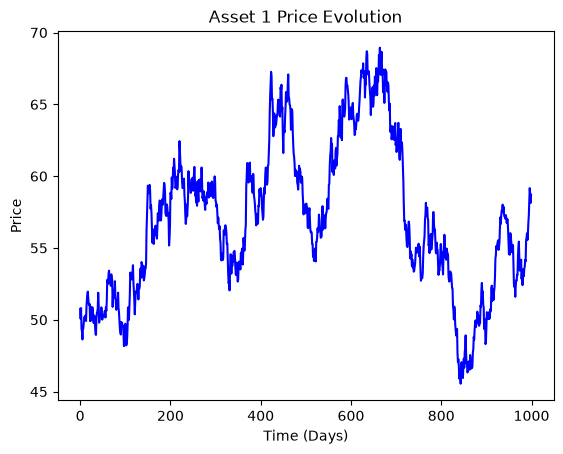

In [33]:
import matplotlib.pyplot as plt

# --- PLOT 1: Asset 1 Price Evolution ---
plt.figure()
plt.plot(df.index, df['Asset_1'], color='blue')
plt.title('Asset 1 Price Evolution')
plt.xlabel('Time (Days)')
plt.ylabel('Price')
plt.show()


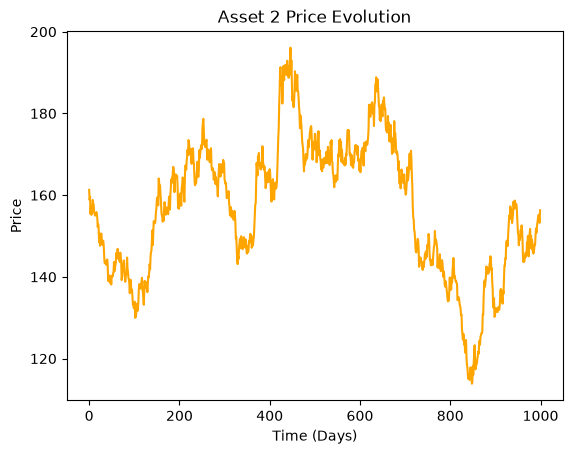

In [34]:

# --- PLOT 2: Asset 2 Price Evolution ---
plt.figure()
plt.plot(df.index, df['Asset_2'], color='orange')
plt.title('Asset 2 Price Evolution')
plt.xlabel('Time (Days)')
plt.ylabel('Price')
plt.show()


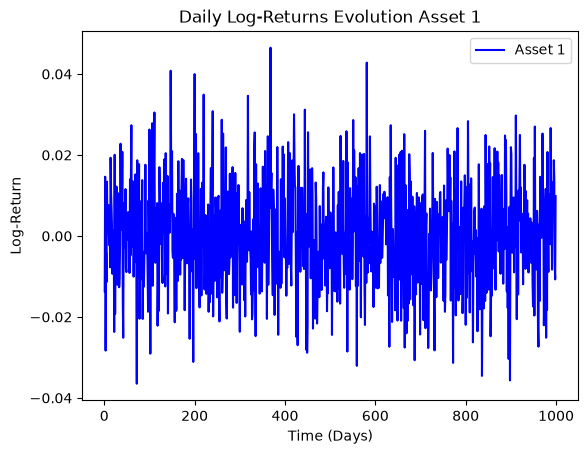

In [35]:

# --- PLOT 3: Log-Returns Evolution ---
plt.figure()
plt.plot(log_returns.index, log_returns['Asset_1'], label='Asset 1', color='blue')
plt.title('Daily Log-Returns Evolution Asset 1')
plt.xlabel('Time (Days)')
plt.ylabel('Log-Return')
plt.legend()
plt.show()


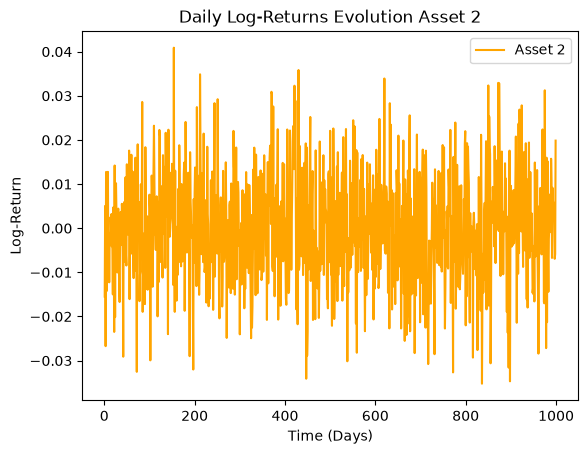

In [36]:

# --- PLOT 3: Log-Returns Evolution ---
plt.figure()
plt.plot(log_returns.index, log_returns['Asset_2'], label='Asset 2', color='orange')
plt.title('Daily Log-Returns Evolution Asset 2')
plt.xlabel('Time (Days)')
plt.ylabel('Log-Return')
plt.legend()
plt.show()


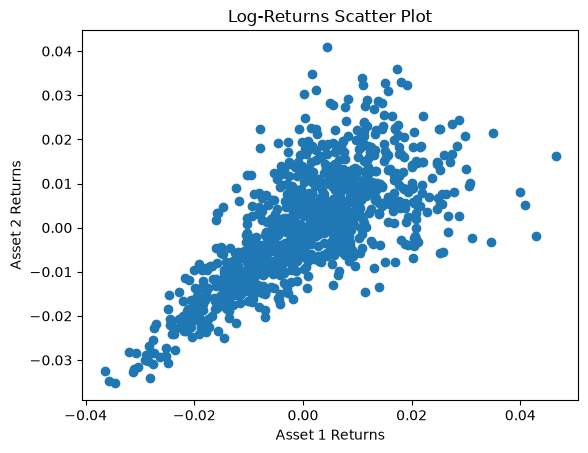

In [37]:

# --- PLOT 4: Scatter Plot for Correlation ---
plt.figure()
plt.scatter(log_returns['Asset_1'], log_returns['Asset_2'])
plt.title('Log-Returns Scatter Plot')
plt.xlabel('Asset 1 Returns')
plt.ylabel('Asset 2 Returns')
plt.show()

C:\Users\adrie\AppData\Local\Temp\ipykernel_22304\1896130057.py:11: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


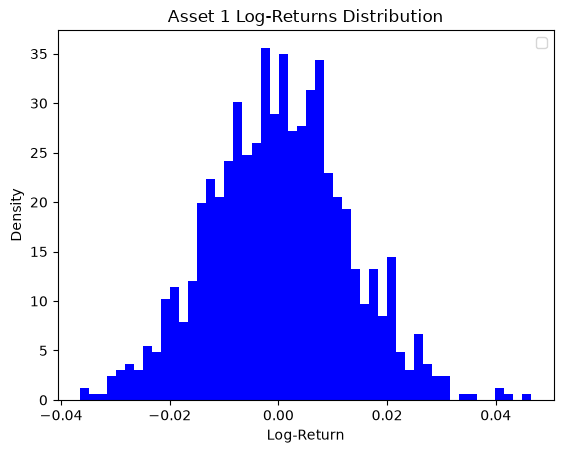

C:\Users\adrie\AppData\Local\Temp\ipykernel_22304\1896130057.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


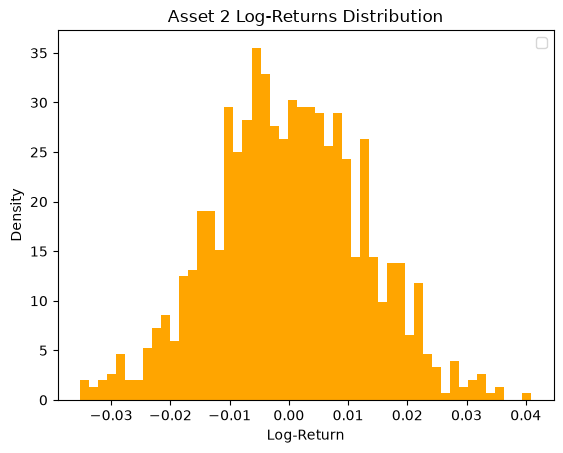

In [38]:
import scipy.stats as stats
import matplotlib.pyplot as plt


plt.figure()
plt.hist(log_returns['Asset_1'], bins=50, density=True, color='blue')

plt.title('Asset 1 Log-Returns Distribution')
plt.xlabel('Log-Return')
plt.ylabel('Density')
plt.legend()
plt.show()

# PLOT 2: Asset 2 Histogram vs Normal
plt.figure()
plt.hist(log_returns['Asset_2'], bins=50, density=True, color='orange')

plt.title('Asset 2 Log-Returns Distribution')
plt.xlabel('Log-Return')
plt.ylabel('Density')
plt.legend()
plt.show()

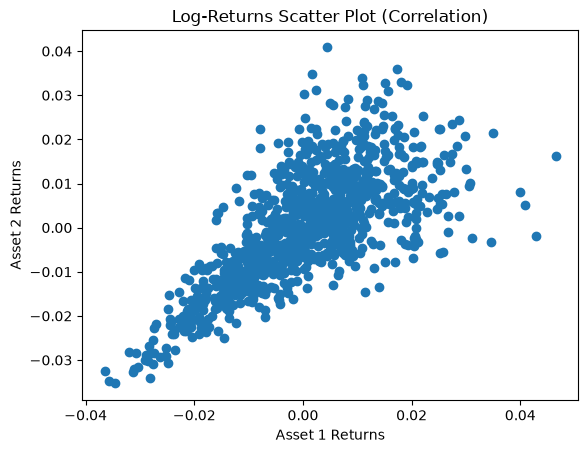

In [39]:
plt.figure()
plt.scatter(log_returns['Asset_1'], log_returns['Asset_2'])
plt.title('Log-Returns Scatter Plot (Correlation)')
plt.xlabel('Asset 1 Returns')
plt.ylabel('Asset 2 Returns')
plt.show()

In [40]:
import numpy as np


X1 = log_returns['Asset_1'].values
X2 = log_returns['Asset_2'].values
n = len(X1)

# 1. Manual Computation of Kendall's Tau

# Step A: The Denominator (Number of combinations: n choose 2)
combinations = (n * (n - 1)) / 2

# Step B: The Numerator (Sum of the signs)
diff_X1 = X1[:, None] - X1
diff_X2 = X2[:, None] - X2

# Multiply the differences and extract the sign function (sgn)
signs = np.sign(diff_X1 * diff_X2)

# np.triu(..., k=1) isolates this upper triangle.
tau_sum = np.sum(np.triu(signs, k=1))

# Step C: Final Calculation
manual_tau = tau_sum / combinations

print("=== MANUAL KENDALL'S TAU ===")
print(f"Number of observations (n): {n}")
print(f"Total pairs evaluated: {combinations:,.0f}")
print(f"Kendall's Tau (τ): {manual_tau:.4f}\n")

# 2. Fitting the Clayton Copula

if manual_tau > 0:
    # Use the mathematical relationship tau = theta / (theta + 2)
    # Rearranged to solve for the Clayton parameter theta:
    theta = (2 * manual_tau) / (1 - manual_tau)
    
    print("=== CLAYTON COPULA FIT ===")
    print(f"Clayton Parameter (θ): {theta:.4f}")
else:
    print("Warning: Clayton copula requires a positive correlation (tau > 0).")

=== MANUAL KENDALL'S TAU ===
Number of observations (n): 999
Total pairs evaluated: 498,501
Kendall's Tau (τ): 0.5525

=== CLAYTON COPULA FIT ===
Clayton Parameter (θ): 2.4692


In [41]:
import numpy as np


X1 = log_returns['Asset_1'].values
X2 = log_returns['Asset_2'].values
n = len(X1)

combinations = (n * (n - 1)) / 2 #2 out of n observations

tau_sum = 0

for k in range(n):
    for l in range(k + 1, n):
        
        diff_X1 = X1[k] - X1[l]
        diff_X2 = X2[k] - X2[l]
        
        pair_sign = np.sign(diff_X1 * diff_X2)
        
        tau_sum += pair_sign

kendall_tau = tau_sum / combinations

print(f"Number of observations (n): {n}")
print(f"Total pairs evaluated: {combinations:,.0f}")
print(f"Kendall's Tau (τ): {kendall_tau:.4f}\n")

theta = (2 * kendall_tau) / (1 - kendall_tau)
print(f"Clayton Parameter (θ): {theta:.4f}")

Number of observations (n): 999
Total pairs evaluated: 498,501
Kendall's Tau (τ): 0.5525

Clayton Parameter (θ): 2.4692


In [42]:
S1_0 = df['Asset_1'].tail(1).values[0]
S1_0

np.float64(58.710146807019285)

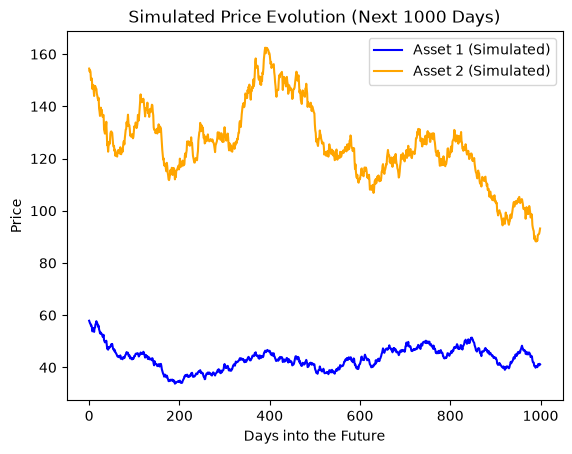

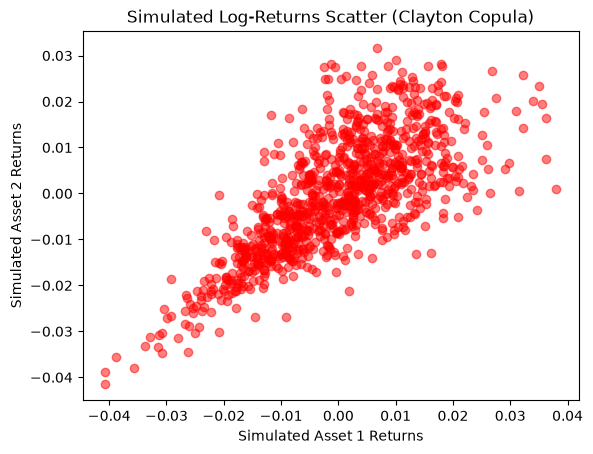

=== SIMULATED STATISTICS ===
Asset 1 Mean : -0.000354
Asset 2 Mean : -0.000517
Asset 1 StDev: 0.012436
Asset 2 StDev: 0.012560


In [43]:
theta = 2.46917
n = 1000

S1_0 = df['Asset_1'].tail(1).values[0]
S2_0 = df['Asset_2'].tail(1).values[0]
mu1 = daily_mean['Asset_1']
mu2 = daily_mean['Asset_2']
vol1 = daily_vol['Asset_1']
vol2 = daily_vol['Asset_2']

u1 = np.random.uniform(0, 1, n)
v = np.random.uniform(0, 1, n)

power_v = -theta / (theta + 1)
u2 = (1 + (u1 ** (-theta)) * ((v ** power_v) - 1)) ** (-1 / theta)

Z1 = norm.ppf(u1)
Z2 = norm.ppf(u2)

sim_returns_1 = mu1 + vol1 * Z1
sim_returns_2 = mu2 + vol2 * Z2

# 4. Generate the Price Trajectories 
# Create empty arrays to hold our 1000 days of prices
sim_prices_1 = np.zeros(n)
sim_prices_2 = np.zeros(n)

# Calculate Day 1 using the starting price
sim_prices_1[0] = S1_0 * np.exp(sim_returns_1[0])
sim_prices_2[0] = S2_0 * np.exp(sim_returns_2[0])

for i in range(1, n):
    # Today's price = Yesterday's price * exp(Today's return)
    sim_prices_1[i] = sim_prices_1[i-1] * np.exp(sim_returns_1[i])
    sim_prices_2[i] = sim_prices_2[i-1] * np.exp(sim_returns_2[i])

# 5. Visual Comparison Plots (Authorized #6)

# Plot 1: Simulated Price Trajectories
plt.figure()
plt.plot(sim_prices_1, label='Asset 1 (Simulated)', color='blue')
plt.plot(sim_prices_2, label='Asset 2 (Simulated)', color='orange')
plt.title('Simulated Price Evolution (Next 1000 Days)')
plt.xlabel('Days into the Future')
plt.ylabel('Price')
plt.legend()
plt.show()

# Plot 2: Simulated Scatter Plot
plt.figure()
plt.scatter(sim_returns_1, sim_returns_2, color='red', alpha=0.5)
plt.title('Simulated Log-Returns Scatter (Clayton Copula)')
plt.xlabel('Simulated Asset 1 Returns')
plt.ylabel('Simulated Asset 2 Returns')
plt.show()

# 6. Basic Statistics Check 
print("=== SIMULATED STATISTICS ===")
print(f"Asset 1 Mean : {np.mean(sim_returns_1):.6f}")
print(f"Asset 2 Mean : {np.mean(sim_returns_2):.6f}")
print(f"Asset 1 StDev: {np.std(sim_returns_1):.6f}")
print(f"Asset 2 StDev: {np.std(sim_returns_2):.6f}")

Step 1: The Partial DerivativeTo figure out what $u_2$ should be, given that we already randomly generated $u_1$, we have to take the partial derivative of your teacher's CDF formula with respect to $u_1$.Let $v$ be a new, independent uniform random number from $U(0,1)$.
$$v = \frac{\partial C(u_1, u_2)}{\partial u_1}$$
If you apply the chain rule to your teacher's formula, the derivative looks like this:
$$v = u_1^{-\theta - 1} \left( u_1^{-\theta} + u_2^{-\theta} - 1 \right)^{-\frac{1}{\theta} - 1}$$
Step 2: Isolating $u_2$In a simulation, the computer has generated $u_1$ and $v$, and it needs to calculate $u_2$. So, we have to do the algebra to get $u_2$ completely by itself on the left side of the equals sign.First, we group the exponents on the right side:
$$v = u_1^{-\theta - 1} \left( u_1^{-\theta} + u_2^{-\theta} - 1 \right)^{-\frac{\theta + 1}{\theta}}$$
We move the $u_1$ term to the other side:
$$v \cdot u_1^{\theta + 1} = \left( u_1^{-\theta} + u_2^{-\theta} - 1 \right)^{-\frac{\theta + 1}{\theta}}$$
We raise both sides to the power of $-\frac{\theta}{\theta + 1}$ to get rid of the big exponent on the right:
$$\left( v \cdot u_1^{\theta + 1} \right)^{-\frac{\theta}{\theta + 1}} = u_1^{-\theta} + u_2^{-\theta} - 1$$
$$v^{-\frac{\theta}{\theta + 1}} \cdot u_1^{-\theta} = u_1^{-\theta} + u_2^{-\theta} - 1$$
Finally, we move everything away from $u_2$ and take the final power to isolate it:
$$u_2^{-\theta} = 1 + u_1^{-\theta} \left( v^{-\frac{\theta}{\theta + 1}} - 1 \right)$$
$$u_2 = \left[ 1 + u_1^{-\theta} \left( v^{-\frac{\theta}{\theta + 1}} - 1 \right) \right]^{-\frac{1}{\theta}}$$

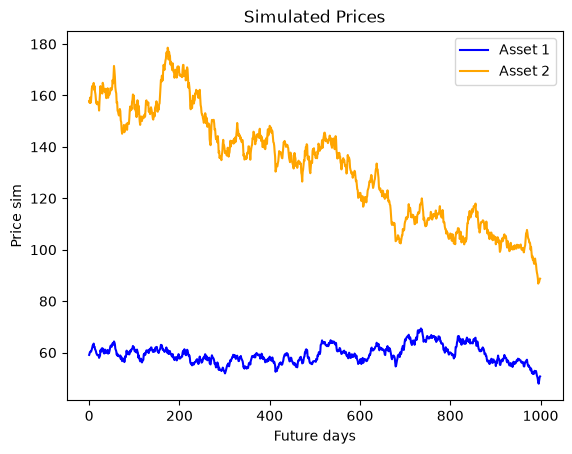

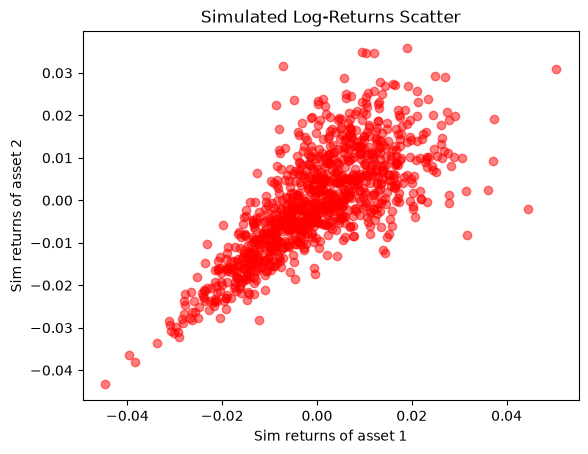

Asset 1 Mean : -0.000146
Asset 2 Mean : -0.000566
Asset 1 StDev: 0.012707
Asset 2 StDev: 0.012342


In [44]:
theta = 2.46917
n = 1000

S1_0 = df['Asset_1'].tail(1).values[0]
S2_0 = df['Asset_2'].tail(1).values[0]
mu1 = daily_mean['Asset_1']
mu2 = daily_mean['Asset_2']
vol1 = daily_vol['Asset_1']
vol2 = daily_vol['Asset_2']

u1 = np.random.uniform(0,1,n)
u_c = np.random.uniform(0,1,n)

u2=(1-u1**(-theta)+u1**(-theta)*u_c**(-theta/(theta+1)))**(-1/theta)

Z1 = norm.ppf(u1)
Z2 = norm.ppf(u2)

sim_returns_1 = mu1 + vol1 * Z1
sim_returns_2 = mu2 + vol2 * Z2

sim_prices_1 = []
sim_prices_2 = []

sim_prices_1.append(S1_0 * np.exp(sim_returns_1[0]))
sim_prices_2.append(S2_0 * np.exp(sim_returns_2[0]))

for i in range(1, n):
    sim_prices_1.append(sim_prices_1[i-1] * np.exp(sim_returns_1[i]))
    sim_prices_2.append(sim_prices_2[i-1] * np.exp(sim_returns_2[i]))


plt.figure()
plt.plot(sim_prices_1, label='Asset 1', color='blue')
plt.plot(sim_prices_2, label='Asset 2', color='orange')
plt.title('Simulated Prices')
plt.xlabel('Future days')
plt.ylabel('Price sim')
plt.legend()
plt.show()

plt.figure()
plt.scatter(sim_returns_1, sim_returns_2, color='red', alpha=0.5)
plt.title('Simulated Log-Returns Scatter')
plt.xlabel('Sim returns of asset 1')
plt.ylabel('Sim returns of asset 2')
plt.show()

print(f"Asset 1 Mean : {np.mean(sim_returns_1):.6f}")
print(f"Asset 2 Mean : {np.mean(sim_returns_2):.6f}")
print(f"Asset 1 StDev: {np.std(sim_returns_1):.6f}")
print(f"Asset 2 StDev: {np.std(sim_returns_2):.6f}")

In [45]:
# Calculate basic daily metrics
sim_mean_1 = np.mean(sim_returns_1)
sim_mean_2 = np.mean(sim_returns_2)
sim_vol_1 = np.std(sim_returns_1)
sim_vol_2 = np.std(sim_returns_2)

sim_ann_drift_1 = (sim_mean_1+(sim_vol_1**2)/2)*252
sim_ann_drift_2 = (sim_mean_2+(sim_vol_2**2)/2)*252
sim_ann_vol_1 = sim_vol_1*np.sqrt(252)
sim_ann_vol_2 = sim_vol_2*np.sqrt(252)

sim_df = pd.DataFrame({ 'Asset 1': sim_returns_1, 'Asset 2': sim_returns_2 })
correlation_sim_mat = sim_df.corr()
correlation_sim=correlation_sim_mat.iloc[0, 1]

print("=== SIMULATED DAILY STATISTICS ===")
print("Daily Mean Log-Return:")
print(f"Asset_1   {sim_mean_1:9.6f}")
print(f"Asset_2   {sim_mean_2:9.6f}")
print("Daily Volatility:")
print(f"Asset_1   {sim_vol_1:9.6f}")
print(f"Asset_2   {sim_vol_2:9.6f}")

print("\n=== SIMULATED ANNUALIZED STATISTICS ===")
print("Annualized Drift (mu):")
print(f"Asset_1   {sim_ann_drift_1:9.6f}")
print(f"Asset_2   {sim_ann_drift_2:9.6f}")
print("Annualized Volatility (sigma):")
print(f"Asset_1   {sim_ann_vol_1:9.6f}")
print(f"Asset_2   {sim_ann_vol_2:9.6f}")

print("\n=== CORRELATION ===")
print(f"Log-Return Correlation between Asset 1 and Asset 2: {correlation_sim:.6f}")

=== SIMULATED DAILY STATISTICS ===
Daily Mean Log-Return:
Asset_1   -0.000146
Asset_2   -0.000566
Daily Volatility:
Asset_1    0.012707
Asset_2    0.012342

=== SIMULATED ANNUALIZED STATISTICS ===
Annualized Drift (mu):
Asset_1   -0.016456
Asset_2   -0.123416
Annualized Volatility (sigma):
Asset_1    0.201715
Asset_2    0.195918

=== CORRELATION ===
Log-Return Correlation between Asset 1 and Asset 2: 0.747772


In [46]:
sim_prices_1

[np.float64(59.103456509661655),
 np.float64(59.72703331828919),
 np.float64(60.28936724458984),
 np.float64(60.41720646051013),
 np.float64(60.31118477617323),
 np.float64(60.727347631511044),
 np.float64(61.37222608844102),
 np.float64(62.03958724762241),
 np.float64(62.83521804757809),
 np.float64(62.57060517923189),
 np.float64(63.49175325780212),
 np.float64(62.177444115231225),
 np.float64(62.29304887257053),
 np.float64(61.313826906662605),
 np.float64(61.0041767821021),
 np.float64(60.51726575039228),
 np.float64(59.71760441826638),
 np.float64(59.37020894120565),
 np.float64(59.02212983087972),
 np.float64(59.10644795736128),
 np.float64(58.89661852325451),
 np.float64(59.06060329032517),
 np.float64(57.95096511311796),
 np.float64(58.54751439211521),
 np.float64(58.71344598496325),
 np.float64(60.951667351021456),
 np.float64(60.33357677347648),
 np.float64(61.01409269402066),
 np.float64(61.65440911691358),
 np.float64(60.8843838954782),
 np.float64(61.615312430234276),
 np.

In [47]:
X1[:,None]

array([[-1.36609533e-02],
       [ 1.46355794e-02],
       [-2.83130964e-02],
       [-4.09814421e-03],
       [-1.13955261e-02],
       [ 1.33846098e-02],
       [ 2.67581611e-03],
       [ 7.13735892e-03],
       [ 7.65706475e-03],
       [ 1.28997560e-03],
       [-2.25211012e-03],
       [ 3.91200097e-03],
       [-7.75849835e-03],
       [ 1.93143145e-02],
       [ 1.06773007e-02],
       [ 7.31450523e-03],
       [ 2.84243192e-03],
       [-9.34416145e-03],
       [-7.03276800e-03],
       [-1.62546757e-03],
       [ 1.40633396e-03],
       [-2.36953385e-02],
       [ 2.00530830e-02],
       [-1.92244517e-02],
       [ 4.69189442e-04],
       [ 5.57800605e-03],
       [ 1.22029079e-02],
       [-4.08129908e-03],
       [-1.20778243e-02],
       [-5.54715784e-03],
       [ 1.05220074e-02],
       [-2.61372841e-03],
       [-1.26671325e-02],
       [-1.01431352e-02],
       [-1.98590355e-03],
       [ 2.27782650e-02],
       [ 8.22681807e-03],
       [ 1.48437485e-03],
       [ 5.0

In [48]:
X1[:,None]-X1

array([[ 0.        , -0.02829653,  0.01465214, ..., -0.00679838,
        -0.00293428, -0.0235034 ],
       [ 0.02829653,  0.        ,  0.04294868, ...,  0.02149815,
         0.02536225,  0.00479313],
       [-0.01465214, -0.04294868,  0.        , ..., -0.02145052,
        -0.01758643, -0.03815554],
       ...,
       [ 0.00679838, -0.02149815,  0.02145052, ...,  0.        ,
         0.00386409, -0.01670502],
       [ 0.00293428, -0.02536225,  0.01758643, ..., -0.00386409,
         0.        , -0.02056912],
       [ 0.0235034 , -0.00479313,  0.03815554, ...,  0.01670502,
         0.02056912,  0.        ]], shape=(999, 999))


ORIGINAL DATA
Kendall's Tau:
  Mean: 0.5522
  Std Dev: 0.0157
  95% CI: [0.5210, 0.5797]

Spearman's Rho:
  Mean: 0.7392
  Std Dev: 0.0170
  95% CI: [0.7053, 0.7689]

SIMULATED DATA
Kendall's Tau:
  Mean: 0.5662
  Std Dev: 0.0172
  95% CI: [0.5335, 0.5960]

Spearman's Rho:
  Mean: 0.7531
  Std Dev: 0.0187
  95% CI: [0.7159, 0.7846]


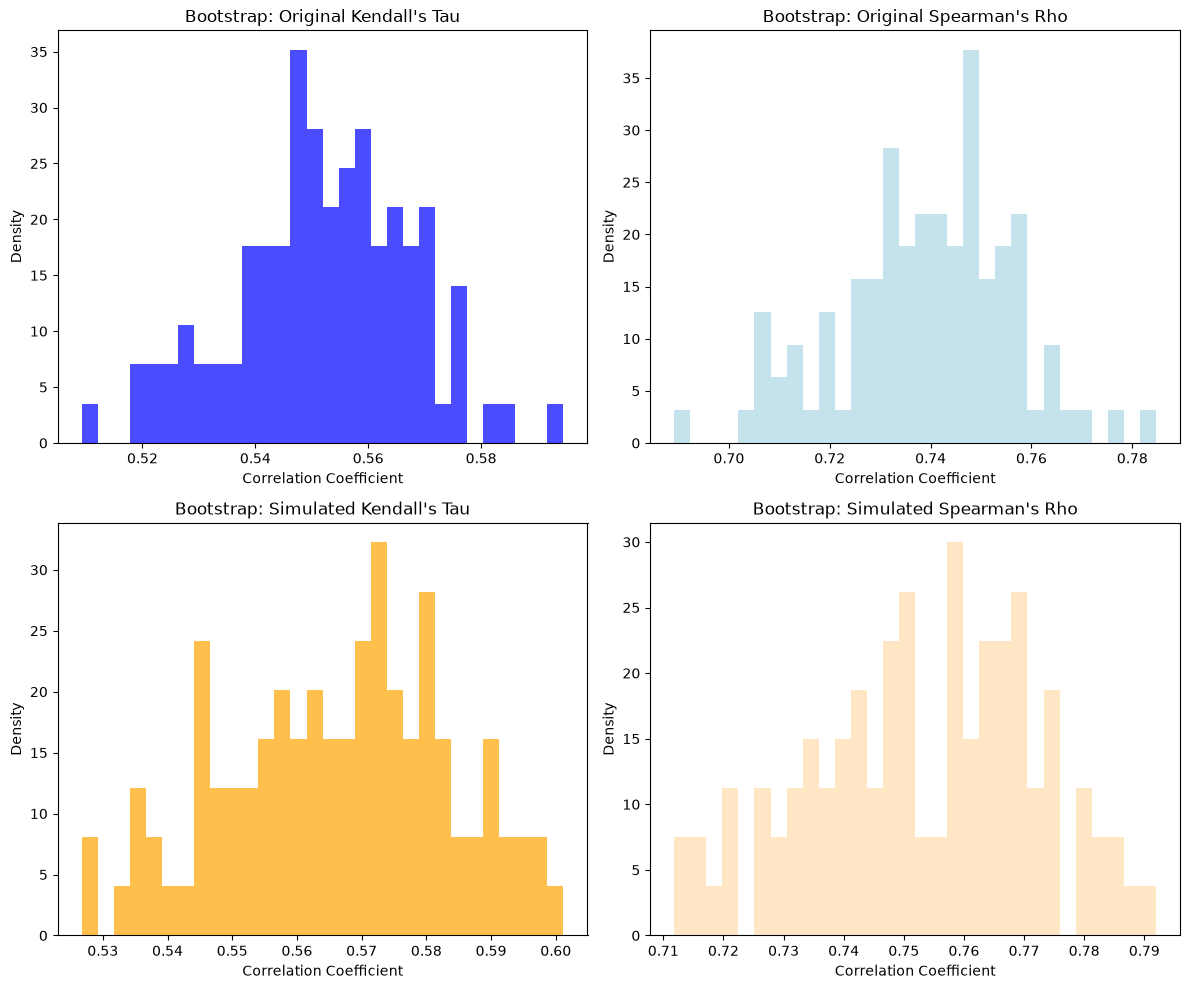

In [49]:
import numpy as np
import matplotlib.pyplot as plt

n_data = len(X1)
n_sim = len(sim_returns_1)

M = 100 

boot_kendall_orig = []
boot_spearman_orig = []
boot_kendall_sim = []
boot_spearman_sim = []


for b in range(M):
    # 1. ORIGINAL DATA BOOTSTRAP
    idx_orig = np.random.randint(0, n_data, n_data)
    x_orig_b = X1[idx_orig]
    y_orig_b = X2[idx_orig]
    
    # Kendall's Rank Correlation (Original)
    tau_sum_orig = 0
    for k in range(n_data):
        for l in range(k + 1, n_data):
            diff_x = x_orig_b[k] - x_orig_b[l]
            diff_y = y_orig_b[k] - y_orig_b[l]
            tau_sum_orig += np.sign(diff_x * diff_y)
            
    combinations_orig = (n_data * (n_data - 1)) / 2
    tau_orig = tau_sum_orig / combinations_orig
    boot_kendall_orig.append(tau_orig)
    
    # Spearman's Rank Correlation (Original)
    rank_x_orig = np.argsort(np.argsort(x_orig_b)) + 1
    rank_y_orig = np.argsort(np.argsort(y_orig_b)) + 1
    
    rho_sum_orig = 0
    for k in range(n_data):
        term_x = rank_x_orig[k] - 0.5 * (n_data + 1)
        term_y = rank_y_orig[k] - 0.5 * (n_data + 1)
        rho_sum_orig += term_x * term_y
        
    rho_orig = (12 / (n_data * (n_data**2 - 1))) * rho_sum_orig
    boot_spearman_orig.append(rho_orig)

    # 2. SIMULATED DATA BOOTSTRAP
    idx_sim = np.random.randint(0, n_sim, n_sim)
    x_sim_b = sim_returns_1[idx_sim]
    y_sim_b = sim_returns_2[idx_sim]
    
    # Kendall's Rank Correlation (Simulated) 
    tau_sum_sim = 0
    for k in range(n_sim):
        for l in range(k + 1, n_sim):
            diff_x = x_sim_b[k] - x_sim_b[l]
            diff_y = y_sim_b[k] - y_sim_b[l]
            tau_sum_sim += np.sign(diff_x * diff_y)
            
    combinations_sim = (n_sim * (n_sim - 1)) / 2
    tau_sim = tau_sum_sim / combinations_sim
    boot_kendall_sim.append(tau_sim)
    
    # Spearman's Rank Correlation (Simulated) 
    rank_x_sim = np.argsort(np.argsort(x_sim_b)) + 1
    rank_y_sim = np.argsort(np.argsort(y_sim_b)) + 1
    
    rho_sum_sim = 0
    for k in range(n_sim):
        term_x = rank_x_sim[k] - 0.5 * (n_sim + 1)
        term_y = rank_y_sim[k] - 0.5 * (n_sim + 1)
        rho_sum_sim += term_x * term_y
        
    rho_sim = (12 / (n_sim * (n_sim**2 - 1))) * rho_sum_sim
    boot_spearman_sim.append(rho_sim)
    

# Convert lists to numpy arrays for final calculations
boot_kendall_orig = np.array(boot_kendall_orig)
boot_spearman_orig = np.array(boot_spearman_orig)
boot_kendall_sim = np.array(boot_kendall_sim)
boot_spearman_sim = np.array(boot_spearman_sim)

# 3. SUMMARY STATISTICS & CONFIDENCE INTERVALS
print("\nORIGINAL DATA")
print("Kendall's Tau:")
print(f"  Mean: {np.mean(boot_kendall_orig):.4f}")
print(f"  Std Dev: {np.std(boot_kendall_orig):.4f}")
print(f"  95% CI: [{np.percentile(boot_kendall_orig, 2.5):.4f}, {np.percentile(boot_kendall_orig, 97.5):.4f}]")

print("\nSpearman's Rho:")
print(f"  Mean: {np.mean(boot_spearman_orig):.4f}")
print(f"  Std Dev: {np.std(boot_spearman_orig):.4f}")
print(f"  95% CI: [{np.percentile(boot_spearman_orig, 2.5):.4f}, {np.percentile(boot_spearman_orig, 97.5):.4f}]")

print("\nSIMULATED DATA")
print("Kendall's Tau:")
print(f"  Mean: {np.mean(boot_kendall_sim):.4f}")
print(f"  Std Dev: {np.std(boot_kendall_sim):.4f}")
print(f"  95% CI: [{np.percentile(boot_kendall_sim, 2.5):.4f}, {np.percentile(boot_kendall_sim, 97.5):.4f}]")

print("\nSpearman's Rho:")
print(f"  Mean: {np.mean(boot_spearman_sim):.4f}")
print(f"  Std Dev: {np.std(boot_spearman_sim):.4f}")
print(f"  95% CI: [{np.percentile(boot_spearman_sim, 2.5):.4f}, {np.percentile(boot_spearman_sim, 97.5):.4f}]")

# 4. PLOTTING
plt.figure(figsize=(12, 10))

# Subplot 1: Original Kendall
plt.subplot(2, 2, 1)
plt.hist(boot_kendall_orig, bins=30, color='blue', alpha=0.7, density=True)
plt.title("Bootstrap: Original Kendall's Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")

# Subplot 2: Original Spearman
plt.subplot(2, 2, 2)
plt.hist(boot_spearman_orig, bins=30, color='lightblue', alpha=0.7, density=True)
plt.title("Bootstrap: Original Spearman's Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")

# Subplot 3: Simulated Kendall
plt.subplot(2, 2, 3)
plt.hist(boot_kendall_sim, bins=30, color='orange', alpha=0.7, density=True)
plt.title("Bootstrap: Simulated Kendall's Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")

# Subplot 4: Simulated Spearman
plt.subplot(2, 2, 4)
plt.hist(boot_spearman_sim, bins=30, color='navajowhite', alpha=0.7, density=True)
plt.title("Bootstrap: Simulated Spearman's Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")

plt.tight_layout()
plt.show()


=== ORIGINAL DATA ===
Kendall's Tau:
  Mean: 0.5529, Std Dev: 0.0164
  95% CI: [0.5204, 0.5853]

Spearman's Rho:
  Mean: 0.7399, Std Dev: 0.0179
  95% CI: [0.7059, 0.7741]

=== SIMULATED DATA ===
Kendall's Tau:
  Mean: 0.5689, Std Dev: 0.0156
  95% CI: [0.5377, 0.5985]

Spearman's Rho:
  Mean: 0.7562, Std Dev: 0.0168
  95% CI: [0.7229, 0.7868]



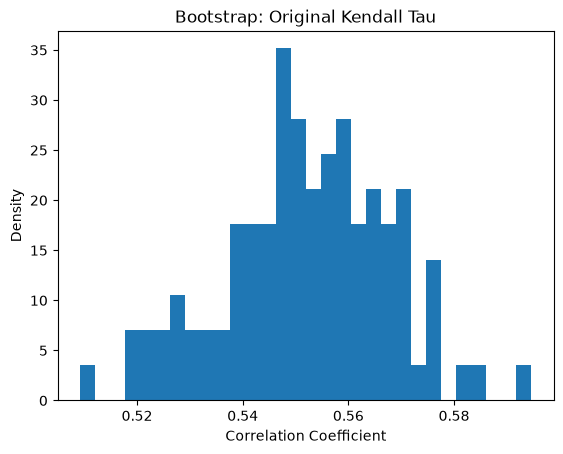

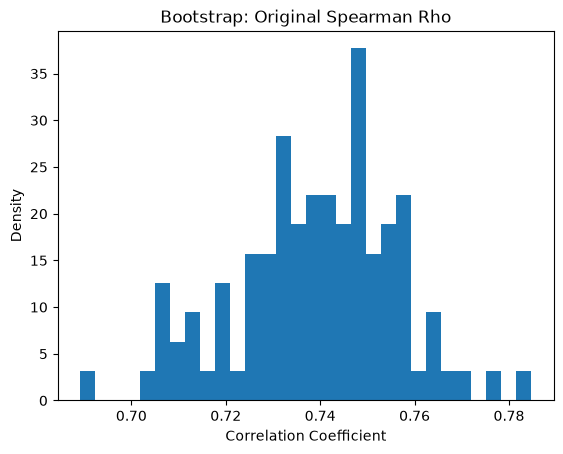

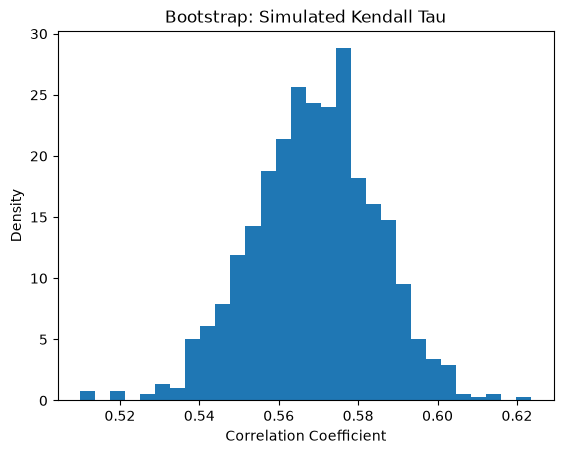

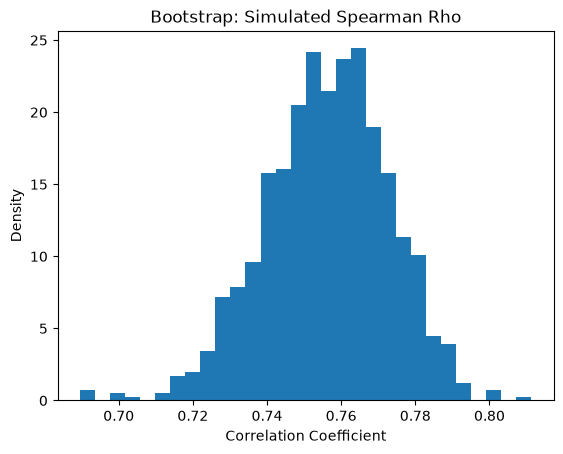

In [50]:
import numpy as np
import matplotlib.pyplot as plt

n_data = len(X1)
n_sim = len(sim_returns_1)

M = 1000 

boot_kendall = []
boot_spearman = []
boot_kendall_sim = []
boot_spearman_sim = []

for b in range(M):
    
    u = np.random.uniform(0, 1, n_data)
    idx = (u*n_data).astype(int)
    
    x_1 = X1[idx]
    x_2 = X2[idx]
    #vectorisation of the prices. Instead of looping throught all pairs like in previous question this time we do a vectorise operation to get the differences of all pairs at once because the computation of the differences was very heavy and doing it 1000 times for a bootstrap would have took way too much time and we be not efficient at all.
    #it would have been like 1 hours
    diff_x_1 = x_1[:, None] - x_1
    diff_x_2 = x_2[:, None] - x_2
    tau = np.sum(np.sign(diff_x_1)*np.sign(diff_x_2))/(n_data*(n_data-1))
    boot_kendall.append(tau)
    
    rank_x_1=np.sum(x_1[:,None]>x_1, axis=1)+1 #so here we are selecting each element of x_1 and comparing it to all the other elements of x_1 to get the values above it and count them and then we add 1 to get the real rank because first rank is 1 not 0
    rank_x_2 = np.sum(x_2[:,None]>x_2, axis=1)+1
    
    term_x_1 = rank_x_1-0.5*(n_data+1)
    term_x_2 = rank_x_2-0.5*(n_data+1)
    rho = (12/(n_data*(n_data**2-1)))*np.sum(term_x_1*term_x_2)
    boot_spearman.append(rho)

    u_sim = np.random.uniform(0, 1, n_sim)
    idx_sim = (u_sim*n_sim).astype(int)
    
    x_1_sim = sim_returns_1[idx_sim]
    X_2_sim = sim_returns_2[idx_sim]
    
    diff_x_1_sim = x_1_sim[:, None]-x_1_sim
    diff_x_2_sim = X_2_sim[:, None]-X_2_sim
    tau_sim = np.sum(np.sign(diff_x_1_sim)*np.sign(diff_x_2_sim))/(n_sim*(n_sim-1))
    boot_kendall_sim.append(tau_sim)
    
    rank_x_1_sim = np.sum(x_1_sim[:, None]>x_1_sim, axis=1)+1
    rank_x_2_sim = np.sum(X_2_sim[:, None]>X_2_sim, axis=1)+1
    term_x_1_sim = rank_x_1_sim-0.5*(n_sim+1)
    term_x_2_sim = rank_x_2_sim-0.5*(n_sim+1)
    rho_sim = (12/(n_sim*(n_sim**2-1)))*np.sum(term_x_1_sim*term_x_2_sim)
    boot_spearman_sim.append(rho_sim)


boot_kendall_orig = np.array(boot_kendall_orig)
boot_spearman_orig = np.array(boot_spearman_orig)
boot_kendall_sim = np.array(boot_kendall_sim)
boot_spearman_sim = np.array(boot_spearman_sim)

mean_kendall=np.mean(boot_kendall)
std_kendall=np.std(boot_kendall)
ci_kendall_95 = [np.percentile(boot_kendall, 2.5), np.percentile(boot_kendall, 97.5)]

mean_kendall_sim=np.mean(boot_kendall_sim)
std_kendall_sim=np.std(boot_kendall_sim)
ci_kendall_sim_95 = [np.percentile(boot_kendall_sim, 2.5), np.percentile(boot_kendall_sim, 97.5)]

mean_spearman=np.mean(boot_spearman)
std_spearman=np.std(boot_spearman)
ci_spearman_95 = [np.percentile(boot_spearman, 2.5), np.percentile(boot_spearman, 97.5)]

mean_spearman_sim=np.mean(boot_spearman_sim)
std_spearman_sim=np.std(boot_spearman_sim)
ci_spearman_sim_95 = [np.percentile(boot_spearman_sim, 2.5), np.percentile(boot_spearman_sim, 97.5)]

print("\n=== ORIGINAL DATA ===")
print("Kendall's Tau:")
print(f"  Mean: {np.mean(boot_kendall):.4f}, Std Dev: {np.std(boot_kendall):.4f}")
print(f"  95% CI: [{np.percentile(boot_kendall, 2.5):.4f}, {np.percentile(boot_kendall, 97.5):.4f}]\n")

print("Spearman's Rho:")
print(f"  Mean: {np.mean(boot_spearman):.4f}, Std Dev: {np.std(boot_spearman):.4f}")
print(f"  95% CI: [{np.percentile(boot_spearman, 2.5):.4f}, {np.percentile(boot_spearman, 97.5):.4f}]\n")

print("=== SIMULATED DATA ===")
print("Kendall's Tau:")
print(f"  Mean: {np.mean(boot_kendall_sim):.4f}, Std Dev: {np.std(boot_kendall_sim):.4f}")
print(f"  95% CI: [{np.percentile(boot_kendall_sim, 2.5):.4f}, {np.percentile(boot_kendall_sim, 97.5):.4f}]\n")

print("Spearman's Rho:")
print(f"  Mean: {np.mean(boot_spearman_sim):.4f}, Std Dev: {np.std(boot_spearman_sim):.4f}")
print(f"  95% CI: [{np.percentile(boot_spearman_sim, 2.5):.4f}, {np.percentile(boot_spearman_sim, 97.5):.4f}]\n")

plt.figure()

plt.plot()
plt.hist(boot_kendall_orig, bins=30, density=True)
plt.title("Bootstrap: Original Kendall Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()

plt.figure()

plt.plot()
plt.hist(boot_spearman_orig, bins=30, density=True)
plt.title("Bootstrap: Original Spearman Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()
# Subplot 3: Simulated Kendall
plt.figure()

plt.plot()
plt.hist(boot_kendall_sim, bins=30, density=True)
plt.title("Bootstrap: Simulated Kendall Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()
# Subplot 4: Simulated Spearman
plt.figure()

plt.plot()
plt.hist(boot_spearman_sim, bins=30, density=True)
plt.title("Bootstrap: Simulated Spearman Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")

plt.show()

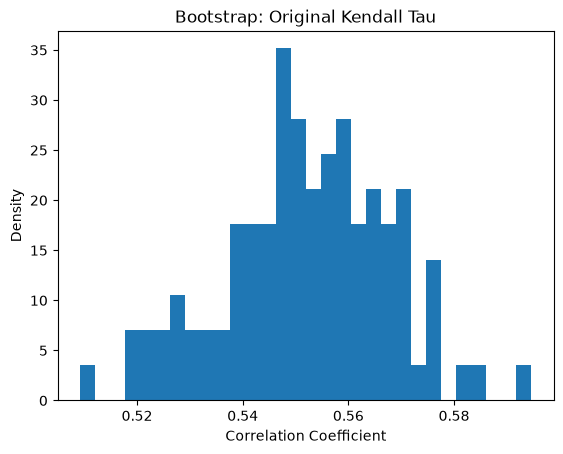

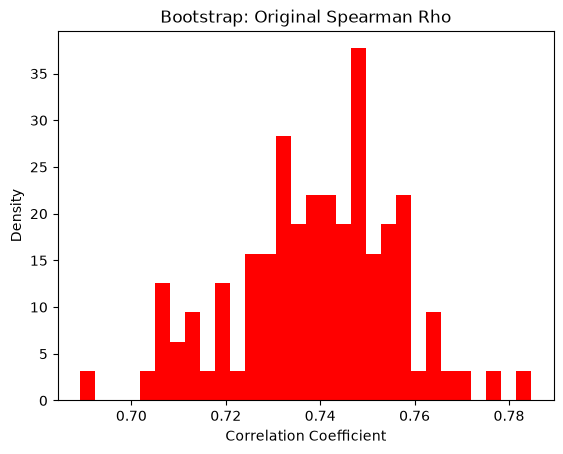

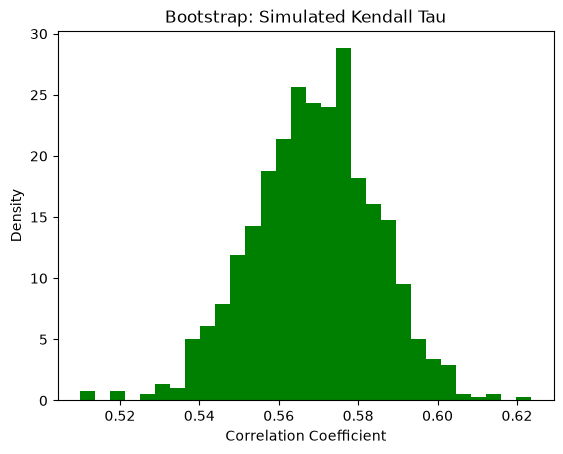

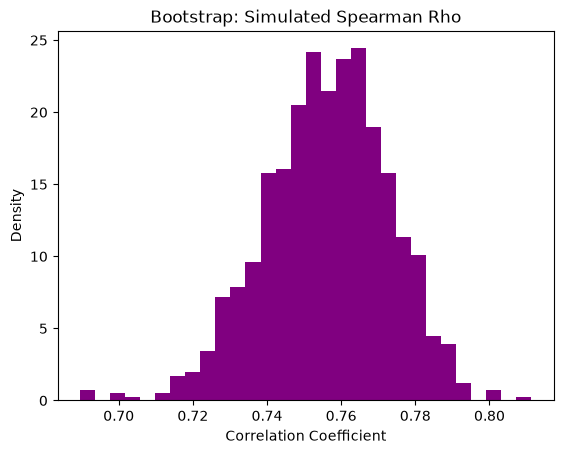

In [51]:
plt.figure()
plt.plot()
plt.hist(boot_kendall_orig, bins=30, density=True)
plt.title("Bootstrap: Original Kendall Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()

plt.figure()
plt.plot()
plt.hist(boot_spearman_orig, bins=30,color="red", density=True)
plt.title("Bootstrap: Original Spearman Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()

plt.figure()
plt.plot()
plt.hist(boot_kendall_sim, bins=30,color="green" ,density=True)
plt.title("Bootstrap: Simulated Kendall Tau")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()

plt.figure()
plt.plot()
plt.hist(boot_spearman_sim, bins=30,color="purple" ,density=True)
plt.title("Bootstrap: Simulated Spearman Rho")
plt.xlabel("Correlation Coefficient")
plt.ylabel("Density")
plt.show()